# 다단계 경보와 결함별 전용 탐지기 비교

기존 최적화 Histogram Gradient Boosting 모델은 교체하지 않습니다. 같은 이상 확률을 세 가지 운영 단계로 해석합니다.

- **이상 징후:** 빠른 화면 표시. 작업 중단이나 외부 알림은 하지 않음
- **조기 경고:** 작업자 확인 요청. 제한적인 오탐 허용
- **확정 경보:** 실제 대응 절차 시작. 낮은 오탐 요구

F1~F4 전용 물리 규칙도 병렬로 비교하지만, 통합 모델보다 낫다는 근거가 있을 때만 경보에 사용합니다. `fault_type`은 전용 규칙 평가를 위한 정답이며 HGB 모델 입력에는 포함되지 않습니다.


## 0. 모델과 예측 데이터

전체 90일 재생 예측으로 단계별 정상 경보량을 정하고, 독립 Test 8개 이벤트에서 단계별 탐지 지연을 계산합니다. 전체 재생은 운영 임계값 교정용이며 독립 성능 평가가 아닙니다.


In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',180);pd.set_option('display.max_columns',30);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

FULL=Path('data/modeling/continuous_replay_predictions.csv.gz');TEST=Path('data/modeling/test_binary_predictions_optimized.csv.gz');EVENT=Path('data/modeling/realtime_event_features.csv.gz')
if not FULL.exists():FULL=Path('../data/modeling/continuous_replay_predictions.csv.gz');TEST=Path('../data/modeling/test_binary_predictions_optimized.csv.gz');EVENT=Path('../data/modeling/realtime_event_features.csv.gz')
full=pd.read_csv(FULL,parse_dates=['timestamp']);test=pd.read_csv(TEST);events=pd.read_csv(EVENT).sort_values(['sample_event_id','relative_min']).reset_index(drop=True)
print(f'전체 재생: {len(full):,}행, 독립 Test 이벤트: {test.sample_event_id.nunique()}개')


전체 재생: 777,600행, 독립 Test 이벤트: 8개


## 1. 단계별 오탐 예산과 임계값

단계별 정상 경보 예산을 먼저 정합니다.

| 단계 | 허용 정상 경보 | 의미 |
|---|---:|---|
| 이상 징후 | 최대 5건/24시간 | 화면 내부 상태 변경 |
| 조기 경고 | 최대 2건/24시간 | 작업자 확인 요청 |
| 확정 경보 | 최대 1건/24시간 | 실제 대응 절차 |

각 단계의 지속시간을 먼저 정하고 전체 정상 재생에서 예산을 만족하는 가장 낮은 임계값을 선택합니다. 낮은 임계값은 일반적으로 더 빠르지만 오탐이 많습니다.


In [2]:
def alert_indices(probability,threshold,persistence):
    signal=np.asarray(probability)>=threshold
    if len(signal)<persistence:return np.array([],dtype=int)
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    return np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])+persistence-1

normal_segments=[]
for _,g in full.groupby('reactor_id'):
    g=g.sort_values('timestamp').reset_index(drop=True);normal=g.fault_type.eq(0);segment=normal.ne(normal.shift(fill_value=normal.iloc[0])).cumsum()
    normal_segments.extend([s.current_probability.to_numpy() for _,s in g[normal].groupby(segment[normal])])
normal_minutes=sum(map(len,normal_segments))

stage_spec={'이상 징후':{'budget':5.0,'persistence':1},'조기 경고':{'budget':2.0,'persistence':2},'확정 경보':{'budget':1.0,'persistence':2}}
stage_rows=[]
for stage,spec in stage_spec.items():
    chosen=None
    for threshold in np.arange(.025,.976,.025):
        count=sum(len(alert_indices(x,threshold,spec['persistence'])) for x in normal_segments);rate=count/(normal_minutes/1440)
        if rate<=spec['budget']:
            chosen={'stage':stage,'threshold':float(round(threshold,3)),'persistence':spec['persistence'],'false_alerts_per_24h':rate,'false_alerts':count};break
    stage_rows.append(chosen)
stages=pd.DataFrame(stage_rows);print(stages.to_string(index=False))


stage  threshold  persistence  false_alerts_per_24h  false_alerts
이상 징후      0.225            1                 4.612          2401
조기 경고      0.250            2                 1.936          1008
확정 경보      0.450            2                 0.957           498


## 2. 독립 Test에서 단계별 탐지 지연

전체 정상 구간으로 정한 임계값을 변경하지 않고 독립 Test 이벤트에 적용합니다. 30분은 고정 대기시간이 아니라 확정 경보의 중앙값입니다. 이상 징후 단계는 더 일찍 표시됩니다.


       events  detected  median_delay_min  min_delay_min  max_delay_min  threshold  persistence  false_alerts_per_24h
stage                                                                                                                
이상 징후       8         8            26.500         15.000         68.000      0.225            1                 4.612
조기 경고       8         8            29.500         16.000         90.000      0.250            2                 1.936
확정 경보       8         8            32.000         17.000         90.000      0.450            2                 0.957

결함 유형별 단계 지연
fault_type      1      2      3      4
stage                                 
이상 징후      49.500 26.000 33.500 16.000
조기 경고      61.000 31.000 36.000 17.000
확정 경보      61.500 31.500 38.000 18.000


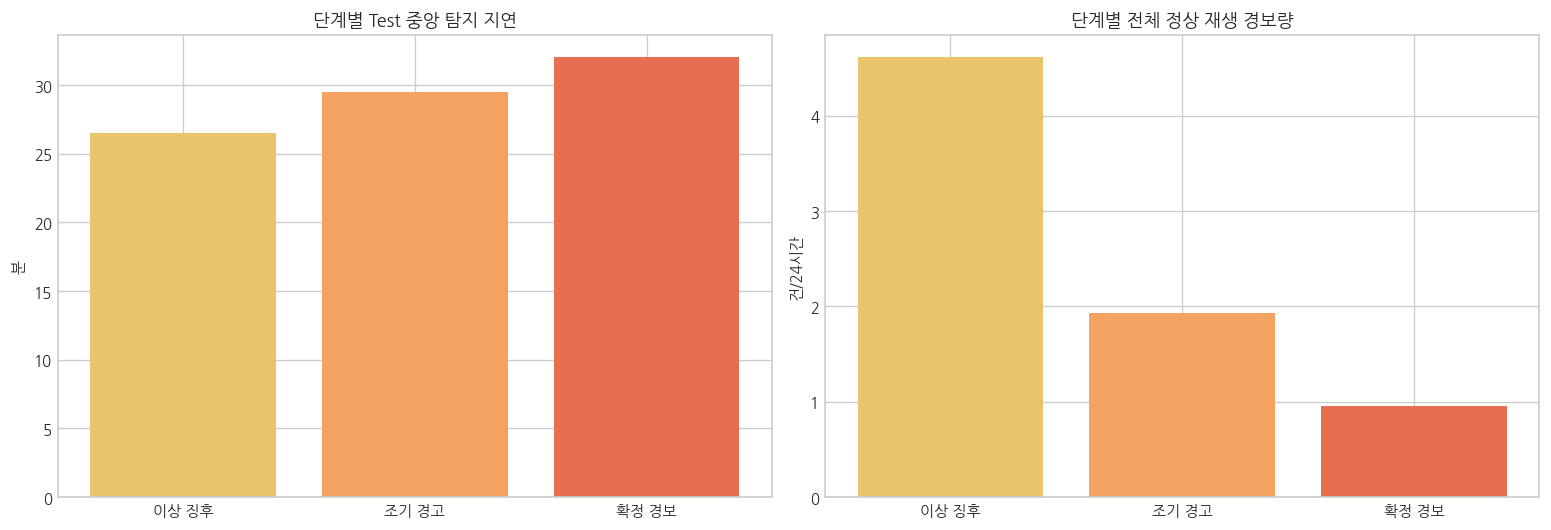

In [3]:
delay_rows=[]
for stage in stages.itertuples():
    for event_id,g in test.groupby('sample_event_id'):
        fault=g[g.sample_kind.eq('post_fault')].sort_values('relative_min');idx=alert_indices(fault.probability,stage.threshold,stage.persistence)
        delay_rows.append({'stage':stage.stage,'event_id':event_id,'fault_type':int(fault.fault_type.iloc[0]),'regime':fault.operating_regime.iloc[0],'detected':len(idx)>0,'delay_min':float(fault.iloc[idx[0]].relative_min) if len(idx) else np.nan})
delays=pd.DataFrame(delay_rows)
stage_summary=delays.groupby('stage').agg(events=('event_id','count'),detected=('detected','sum'),median_delay_min=('delay_min','median'),min_delay_min=('delay_min','min'),max_delay_min=('delay_min','max')).reindex(stages.stage)
stage_summary=stage_summary.join(stages.set_index('stage')[['threshold','persistence','false_alerts_per_24h']]);print(stage_summary.to_string())

print('\n결함 유형별 단계 지연')
print(delays.groupby(['stage','fault_type']).delay_min.median().unstack().reindex(stages.stage).to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5));axes[0].bar(stage_summary.index,stage_summary.median_delay_min,color=['#e9c46a','#f4a261','#e76f51']);axes[0].set_title('단계별 Test 중앙 탐지 지연');axes[0].set_ylabel('분');axes[1].bar(stage_summary.index,stage_summary.false_alerts_per_24h,color=['#e9c46a','#f4a261','#e76f51']);axes[1].set_title('단계별 전체 정상 재생 경보량');axes[1].set_ylabel('건/24시간');plt.tight_layout();plt.show()


## 3. 결함별 전용 물리 점수 실험

결함 정의에 맞춰 과거 6시간 기준 15분 EWMA z-score를 조합합니다.

- F1: 온도 상승 + 냉각수 유량 감소
- F2: 원료 유량 감소 + 전환율 감소
- F3: 온도 변화와 반응률의 불일치, 단 냉각수 감소 영향 차감
- F4: 진동 상승 + 모터 전류 상승

이 규칙은 설명하기 쉽지만 정상 운전 변화나 다른 결함에서도 같은 방향이 나타날 수 있습니다.


In [4]:
score_sensors=['reactor_temp','coolant_flow_rate','feed_flow_rate','conversion_rate','vibration_rms','motor_current','reaction_rate'];grouped=events.groupby('sample_event_id');parts=[]
for col in score_sensors:
    mean6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean());std6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan);ewma=grouped[col].transform(lambda x:x.ewm(span=15,adjust=False).mean());parts.append(pd.Series((ewma-mean6)/std6,name=f'{col}__ewma_z'))
events=pd.concat([events,pd.concat(parts,axis=1)],axis=1);pos=lambda x:np.maximum(x,0)
events['F1_score']=pos(events.reactor_temp__ewma_z)+pos(-events.coolant_flow_rate__ewma_z)
events['F2_score']=pos(-events.feed_flow_rate__ewma_z)+pos(-events.conversion_rate__ewma_z)
events['F3_score']=(pos(events.reactor_temp__ewma_z)+.5*pos((events.reactor_temp__ewma_z-events.reaction_rate__ewma_z).abs())-.75*pos(-events.coolant_flow_rate__ewma_z)).clip(lower=0)
events['F4_score']=pos(events.vibration_rms__ewma_z)+pos(events.motor_current__ewma_z)

rule_rows=[];selected_rules={}
for fault_type in [1,2,3,4]:
    score=f'F{fault_type}_score';validation=events[events.split.eq('validation')];candidates=[]
    for persistence in [1,2,3,5]:
        for threshold in np.arange(.5,8.01,.25):
            target_delays=[];false_alerts=0;normal_hours=0
            for _,g in validation.groupby('sample_event_id'):
                g=g.sort_values('relative_min');normal=g[g.sample_kind.eq('pre_normal')];normal_hours+=len(normal)/60;false_alerts+=len(alert_indices(normal[score],threshold,persistence));target=g[(g.sample_kind.eq('post_fault'))&g.fault_type.eq(fault_type)]
                if len(target):
                    idx=alert_indices(target[score],threshold,persistence);target_delays.append(target.iloc[idx[0]].relative_min if len(idx) else np.nan)
            rate=false_alerts/normal_hours*24
            if len(target_delays) and np.isfinite(target_delays).all() and rate<=2:candidates.append({'threshold':threshold,'persistence':persistence,'median_delay':np.median(target_delays),'false_alerts_per_24h':rate})
    best=pd.DataFrame(candidates).sort_values(['median_delay','false_alerts_per_24h','threshold'],ascending=[True,True,False]).iloc[0];selected_rules[fault_type]={'threshold':float(best.threshold),'persistence':int(best.persistence)};rule_rows.append({'fault_type':fault_type,**best.to_dict()})
rule_results=pd.DataFrame(rule_rows);print(rule_results.to_string(index=False))


 fault_type  threshold  persistence  median_delay  false_alerts_per_24h
          1      1.000        2.000        45.500                 1.750
          2      0.750        5.000        13.000                 2.000
          3      0.750        2.000        58.000                 0.500
          4      1.250        1.000        23.500                 0.375


## 4. 전용 탐지기를 경보에 채택하지 않은 이유

전용 점수를 동시에 실행하면 F1·F2 점수가 F3나 F4 이벤트에서도 상승했습니다. Validation 기준 결함 유형 힌트 정확도는 낮고, 두 빠른 규칙만 결합해도 정상 경보가 약 3.75건/24시간 발생했습니다.

F1 규칙은 F1 탐지를 일부 앞당겼지만 전체 경보 시스템에 추가할 만큼 선택적이지 않았습니다. F2와 F4는 기존 HGB가 이미 빠르게 탐지했고 F3 규칙은 개선이 없었습니다. 따라서 전용 점수는 경보 발생 후 원인 설명 패널에 표시하되 실제 경보 트리거로는 사용하지 않습니다.


In [5]:
# F1/F2 빠른 규칙을 동시에 켰을 때의 Validation 진단
combined_rows=[];false_alerts=0;normal_hours=0
for event_id,g in events[events.split.eq('validation')].groupby('sample_event_id'):
    g=g.sort_values('relative_min');normal=g[g.sample_kind.eq('pre_normal')];normal_hours+=len(normal)/60
    normal_hits=[]
    for f in [1,2]:
        rule=selected_rules[f];hit=np.zeros(len(normal),dtype=bool);hit[alert_indices(normal[f'F{f}_score'],rule['threshold'],rule['persistence'])]=True;normal_hits.append(hit)
    false_alerts+=np.any(np.vstack(normal_hits),axis=0).sum()
    fault=g[g.sample_kind.eq('post_fault')];options=[]
    for f in [1,2]:
        rule=selected_rules[f];idx=alert_indices(fault[f'F{f}_score'],rule['threshold'],rule['persistence'])
        if len(idx):options.append((float(fault.iloc[idx[0]].relative_min),f))
    if options:
        delay,predicted=min(options);combined_rows.append({'event_id':event_id,'true_fault':int(fault.fault_type.iloc[0]),'predicted_hint':predicted,'delay_min':delay})
combined=pd.DataFrame(combined_rows);print(combined.to_string(index=False));print(f"\n결합 정상 경보: {false_alerts/normal_hours*24:.3f}건/24시간");print(f"힌트 정확도: {(combined.true_fault==combined.predicted_hint).mean():.3f}")


 event_id  true_fault  predicted_hint  delay_min
       12           3               2     11.000
       18           3               1     76.000
       22           2               2     15.000
       25           2               2     11.000
       26           1               1     56.000
       27           4               2    242.000
       30           1               1     35.000

결합 정상 경보: 3.750건/24시간
힌트 정확도: 0.571


## 5. 최종 다단계 정책 저장

모델은 기존 최적화 HGB를 그대로 사용하고 경보 상태 전이만 추가합니다. 단계가 내려갈 때는 즉시 해제하지 않고 일정 시간 정상 확률이 유지되는 hysteresis를 구현하는 것이 좋습니다. 이번 노트북은 진입 규칙까지만 정의합니다.


In [6]:
config={'model_file':'models/binary_fault_detector_hgb_optimized.joblib','model_unchanged':True,'stages':{r.stage:{'probability_threshold':float(r.threshold),'persistence_minutes':int(r.persistence),'normal_alert_budget_per_24h':float(stage_spec[r.stage]['budget']),'observed_full_replay_alerts_per_24h':float(r.false_alerts_per_24h),'independent_test_median_delay_min':float(stage_summary.loc[r.stage,'median_delay_min'])} for r in stages.itertuples()},'specialized_detectors':{'status':'diagnostic_only_not_alarm_triggers','rules':selected_rules,'reason':'Combined rules increased false alerts and produced ambiguous fault hints.'},'limitations':['Threshold budgets were calibrated on the available 90-day normal data.','Only eight independent test events are available.','A separate hysteresis and alert-clear policy is still required.']}
path=Path('models/multistage_alarm_config.json');path.write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8');delays.to_csv('data/modeling/test_multistage_alarm_delays.csv',index=False);print(path)


models/multistage_alarm_config.json


## 6. 결론

- 기존 HGB 모델은 그대로 유지했습니다.
- 하나의 확정 경보 대신 이상 징후·조기 경고·확정 경보의 세 단계로 운영합니다.
- 독립 Test 중앙 지연은 각각 약 26.5분, 29.5분, 32분입니다.
- 더 빠른 이상 징후는 작업 중단 신호가 아니라 화면 표시와 관찰 강화에 사용합니다.
- 결함별 물리 점수는 설명에는 유용하지만 경보 트리거로 사용하면 오탐과 유형 혼동이 증가했습니다.

다음 구현 단계에서는 대시보드 상태 전이, 경보 해제 조건, 알림 억제 시간과 유형 예측 갱신 주기를 정의해야 합니다.
